# Лабораторная работа 7. Кластеризация данных

Набор данных: Wine (sklearn.datasets.load_wine). Алгоритмы: K-means, иерархическая кластеризация, GMM, DBSCAN. Целевой признак исключён из обучения и используется только для внешней оценки качества. Модели обучаются на исходных стандартизованных признаках, в пространстве главных компонент (PCA) и в пространстве t-SNE.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    homogeneity_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 17
BASE = Path.cwd()
FIG_DIR = BASE / "figures"
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150)
    plt.show()

## 1. Загрузка данных (целевой признак исключается из обучения)

In [2]:
wine = load_wine(as_frame=True)
X_raw = wine.data.copy()
y_true = wine.target.copy()  # используется только для внешней оценки
print("Размер:", X_raw.shape)
print("Пропуски:", int(X_raw.isna().sum().sum()), " Дубликаты:", int(X_raw.duplicated().sum()))
print(X_raw.describe().T[["mean", "std", "min", "max"]].round(2))
print("Классы (только для проверки):", y_true.value_counts().sort_index().to_dict())

Размер: (178, 13)
Пропуски: 0  Дубликаты: 0
                                mean     std     min      max
alcohol                        13.00    0.81   11.03    14.83
malic_acid                      2.34    1.12    0.74     5.80
ash                             2.37    0.27    1.36     3.23
alcalinity_of_ash              19.49    3.34   10.60    30.00
magnesium                      99.74   14.28   70.00   162.00
total_phenols                   2.30    0.63    0.98     3.88
flavanoids                      2.03    1.00    0.34     5.08
nonflavanoid_phenols            0.36    0.12    0.13     0.66
proanthocyanins                 1.59    0.57    0.41     3.58
color_intensity                 5.06    2.32    1.28    13.00
hue                             0.96    0.23    0.48     1.71
od280/od315_of_diluted_wines    2.61    0.71    1.27     4.00
proline                       746.89  314.91  278.00  1680.00
Классы (только для проверки): {0: 59, 1: 71, 2: 48}


## 2. Выбросы (правило Тьюки) и стандартизация

Выбросы по признакам:
 malic_acid           3
ash                  3
alcalinity_of_ash    4
magnesium            4
proanthocyanins      2
color_intensity      4
hue                  1
dtype: int64
Объектов с хотя бы одним выбросом: 17
Объектов с >=2 выбросами: 4
После очистки: (174, 13)  удалено: 4


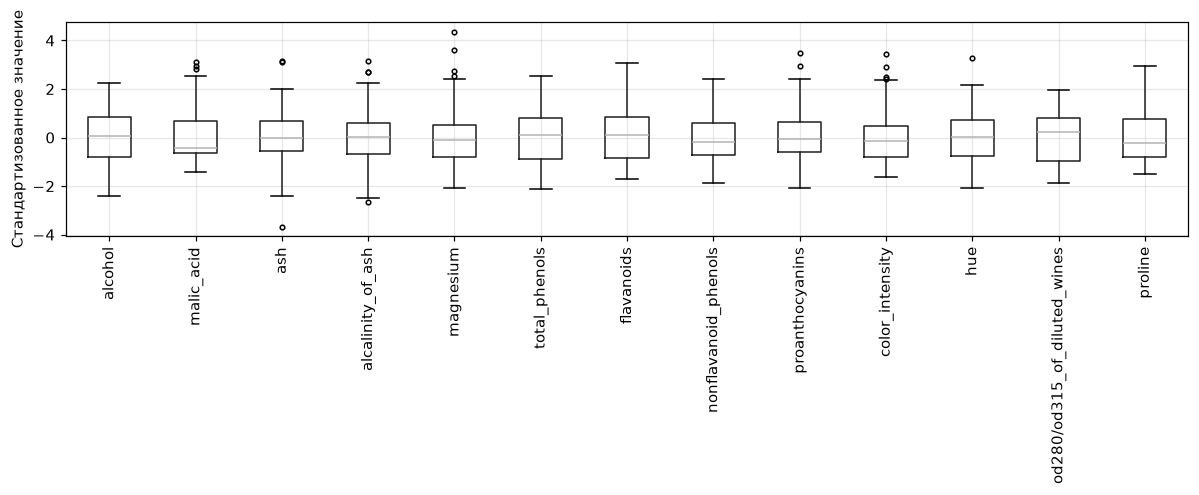

Среднее после стандартизации ~ -0.0  std ~ 1.0


In [3]:
q1, q3 = X_raw.quantile(0.25), X_raw.quantile(0.75)
iqr = q3 - q1
mask_out = (X_raw < q1 - 1.5 * iqr) | (X_raw > q3 + 1.5 * iqr)
out_per_feature = mask_out.sum()
print("Выбросы по признакам:\n", out_per_feature[out_per_feature > 0])
n_out_feat = mask_out.sum(axis=1)
print("Объектов с хотя бы одним выбросом:", int((n_out_feat > 0).sum()))
print("Объектов с >=2 выбросами:", int((n_out_feat >= 2).sum()))

# Удаляем объекты, у которых выбросы сразу по двум и более признакам
keep = n_out_feat < 2
X_clean = X_raw[keep].reset_index(drop=True)
y_clean = y_true[keep].reset_index(drop=True)
print("После очистки:", X_clean.shape, " удалено:", int((~keep).sum()))

plt.figure(figsize=(11, 4.5))
Z_raw = (X_raw - X_raw.mean()) / X_raw.std()
Z_raw.boxplot(rot=90, flierprops=dict(marker="o", markersize=3))
plt.ylabel("Стандартизованное значение")
savefig("boxplot.png")

scaler = StandardScaler()
X = scaler.fit_transform(X_clean)
print("Среднее после стандартизации ~", np.round(X.mean(), 6), " std ~", np.round(X.std(), 6))

## 3. Понижение размерности: PCA и t-SNE

Доли дисперсии PC: [0.373 0.198 0.097 0.073 0.064]
Накопленная доля для 2/3/8 компонент: [0.571 0.667 0.922]
Компонент для 90 % дисперсии: 8


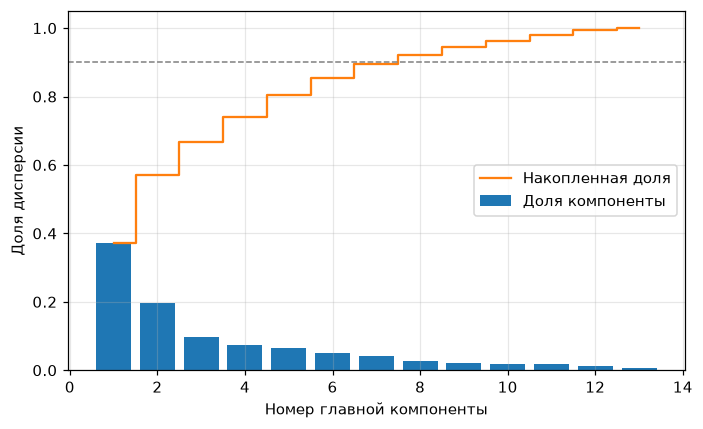

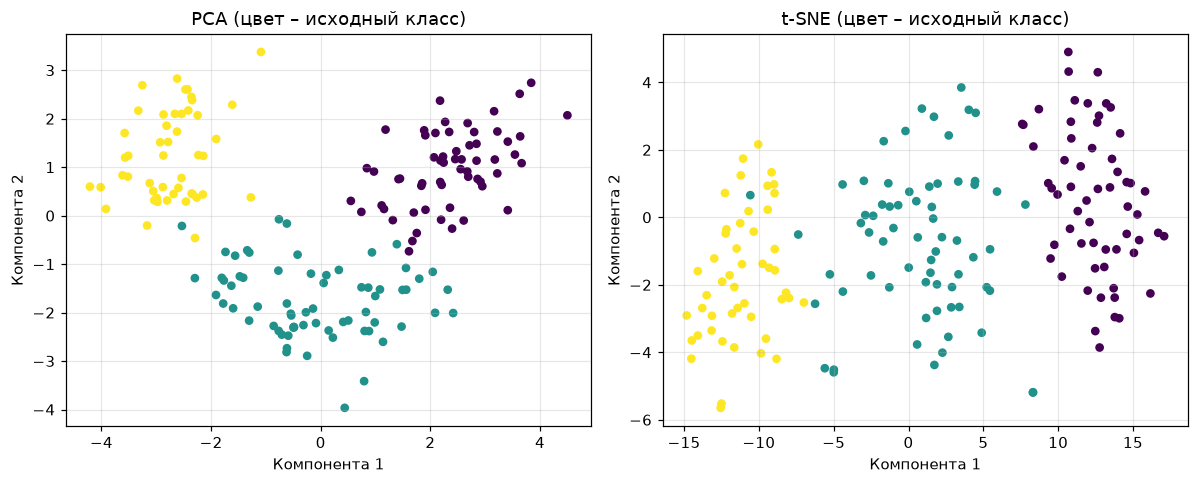

In [4]:
pca_full = PCA().fit(X)
cum = np.cumsum(pca_full.explained_variance_ratio_)
print("Доли дисперсии PC:", np.round(pca_full.explained_variance_ratio_[:5], 3))
print("Накопленная доля для 2/3/8 компонент:", np.round(cum[[1, 2, 7]], 3))
n_pc90 = int(np.searchsorted(cum, 0.90) + 1)
print("Компонент для 90 % дисперсии:", n_pc90)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(range(1, len(cum) + 1), pca_full.explained_variance_ratio_, label="Доля компоненты")
ax.step(range(1, len(cum) + 1), cum, where="mid", color="C1", label="Накопленная доля")
ax.axhline(0.9, color="gray", ls="--", lw=1)
ax.set_xlabel("Номер главной компоненты")
ax.set_ylabel("Доля дисперсии")
ax.legend()
savefig("pca_variance.png")

pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca2.fit_transform(X)
X_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, emb, title in zip(axes, [X_pca, X_tsne], ["PCA", "t-SNE"]):
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=y_clean, cmap="viridis", s=22)
    ax.set_title(title + " (цвет – исходный класс)")
    ax.set_xlabel("Компонента 1")
    ax.set_ylabel("Компонента 2")
savefig("pca_tsne_true.png")

## 4-5. Подбор числа кластеров для k-means

 k  Inertia  Silhouette  Davies-Bouldin  Calinski-Harabasz
 2 1602.344       0.273           1.448             70.809
 3 1217.377       0.292           1.355             73.367
 4 1121.800       0.250           1.738             57.596
 5 1054.863       0.208           1.835             48.349
 6 1009.668       0.176           1.866             41.675
 7  956.527       0.143           1.885             37.987
 8  899.840       0.149           1.811             35.898
 9  872.264       0.134           1.806             32.861
10  832.345       0.138           1.726             31.299
Лучшее k по силуэту: 3


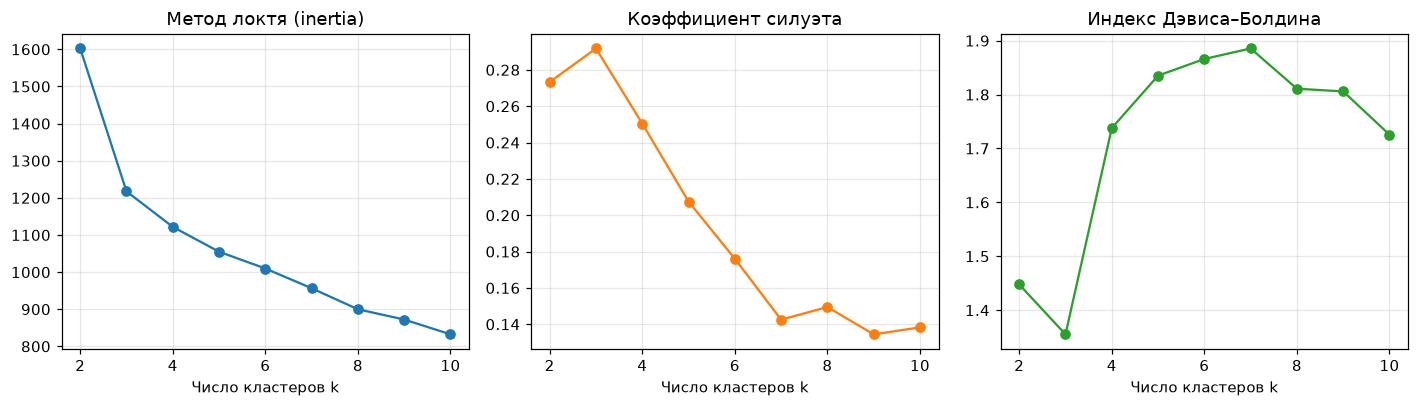

In [5]:
ks = range(2, 11)
rows = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    rows.append(
        {
            "k": k,
            "Inertia": km.inertia_,
            "Silhouette": silhouette_score(X, km.labels_),
            "Davies-Bouldin": davies_bouldin_score(X, km.labels_),
            "Calinski-Harabasz": calinski_harabasz_score(X, km.labels_),
        }
    )
k_table = pd.DataFrame(rows)
print(k_table.round(3).to_string(index=False))
best_k = int(k_table.loc[k_table["Silhouette"].idxmax(), "k"])
print("Лучшее k по силуэту:", best_k)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].plot(k_table["k"], k_table["Inertia"], "o-")
axes[0].set_title("Метод локтя (inertia)")
axes[1].plot(k_table["k"], k_table["Silhouette"], "o-", color="C1")
axes[1].set_title("Коэффициент силуэта")
axes[2].plot(k_table["k"], k_table["Davies-Bouldin"], "o-", color="C2")
axes[2].set_title("Индекс Дэвиса–Болдина")
for ax in axes:
    ax.set_xlabel("Число кластеров k")
savefig("k_selection.png")

## Иерархическая кластеризация: дендрограмма и сравнение связей

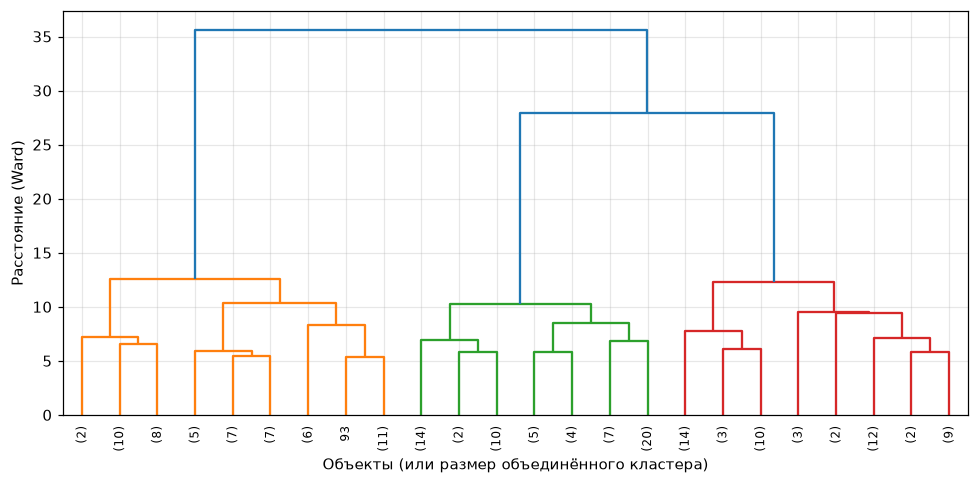

   Связь  Silhouette    ARI
    ward       0.284  0.806
complete       0.212  0.636
 average       0.254  0.466
  single       0.187 -0.004


In [6]:
Z = linkage(X, method="ward")
plt.figure(figsize=(9, 4.5))
dendrogram(Z, truncate_mode="lastp", p=24, leaf_rotation=90, leaf_font_size=8, color_threshold=(Z[-3, 2] + Z[-2, 2]) / 2)
plt.xlabel("Объекты (или размер объединённого кластера)")
plt.ylabel("Расстояние (Ward)")
savefig("dendrogram.png")

link_rows = []
for link in ["ward", "complete", "average", "single"]:
    lab = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(X)
    link_rows.append(
        {
            "Связь": link,
            "Silhouette": silhouette_score(X, lab),
            "ARI": adjusted_rand_score(y_clean, lab),
        }
    )
link_table = pd.DataFrame(link_rows)
print(link_table.round(3).to_string(index=False))

## GMM: выбор числа компонент по BIC

In [7]:
gmm_rows = []
for k in ks:
    g = GaussianMixture(n_components=k, covariance_type="diag", n_init=5, random_state=RANDOM_STATE).fit(X)
    gmm_rows.append({"k": k, "BIC": g.bic(X), "AIC": g.aic(X)})
gmm_table = pd.DataFrame(gmm_rows)
print(gmm_table.round(1).to_string(index=False))
best_gmm_k = int(gmm_table.loc[gmm_table["BIC"].idxmin(), "k"])
print("Лучшее число компонент GMM по BIC:", best_gmm_k)

 k    BIC    AIC
 2 5830.7 5663.2
 3 5370.8 5118.0
 4 5362.2 5024.1
 5 5334.5 4911.2
 6 5390.3 4881.7
 7 5449.0 4855.1
 8 5460.1 4780.9
 9 5569.8 4805.3
10 5583.7 4733.9
Лучшее число компонент GMM по BIC: 5


## DBSCAN: k-расстояния и подбор eps / min_samples

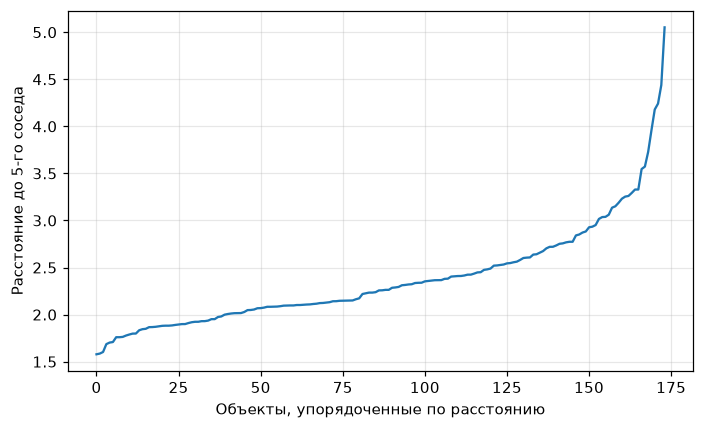

 eps  min_samples  clusters  noise  Silhouette   ARI
 2.4            5         2  0.195       0.323 0.411
 2.4            4         2  0.178       0.322 0.425
 2.6           10         2  0.149       0.316 0.446
 2.5            8         2  0.184       0.315 0.416
 2.3            3         3  0.167       0.223 0.409
 2.4            3         3  0.149       0.222 0.425
Выбраны eps = 2.4  min_samples = 5


In [8]:
min_samples_k = 2 * X.shape[1]  # правило 2*d для k-расстояния
dist = NearestNeighbors(n_neighbors=5).fit(X).kneighbors(X)[0][:, -1]
plt.figure(figsize=(6.5, 4))
plt.plot(np.sort(dist))
plt.xlabel("Объекты, упорядоченные по расстоянию")
plt.ylabel("Расстояние до 5-го соседа")
savefig("kdistance.png")

db_rows = []
for eps in np.arange(1.8, 4.01, 0.1):
    for ms in [3, 4, 5, 6, 8, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        noise = float(np.mean(lab == -1))
        if n_cl >= 2 and noise <= 0.2:
            m = lab != -1
            db_rows.append(
                {
                    "eps": round(eps, 1),
                    "min_samples": ms,
                    "clusters": n_cl,
                    "noise": noise,
                    "Silhouette": silhouette_score(X[m], lab[m]),
                    "ARI": adjusted_rand_score(y_clean, lab),
                }
            )
db_table = pd.DataFrame(db_rows)
print(db_table.sort_values("Silhouette", ascending=False).head(8).round(3).to_string(index=False))
best_db = db_table.sort_values("Silhouette", ascending=False).iloc[0]
EPS, MS = float(best_db["eps"]), int(best_db["min_samples"])
print("Выбраны eps =", EPS, " min_samples =", MS)

## 6. Итоговое сравнение алгоритмов

            Алгоритм  Кластеров  Шум, %  Silhouette  Davies-Bouldin  Calinski-Harabasz   ARI   NMI  Homogeneity
             K-means          3    0.00       0.292           1.355             73.367 0.950 0.938        0.940
Иерархическая (Ward)          3    0.00       0.284           1.371             70.625 0.806 0.803        0.805
                 GMM          3    0.00       0.287           1.377             72.060 0.896 0.864        0.866
              DBSCAN          2   19.54       0.323           1.201             69.990 0.411 0.504        0.481


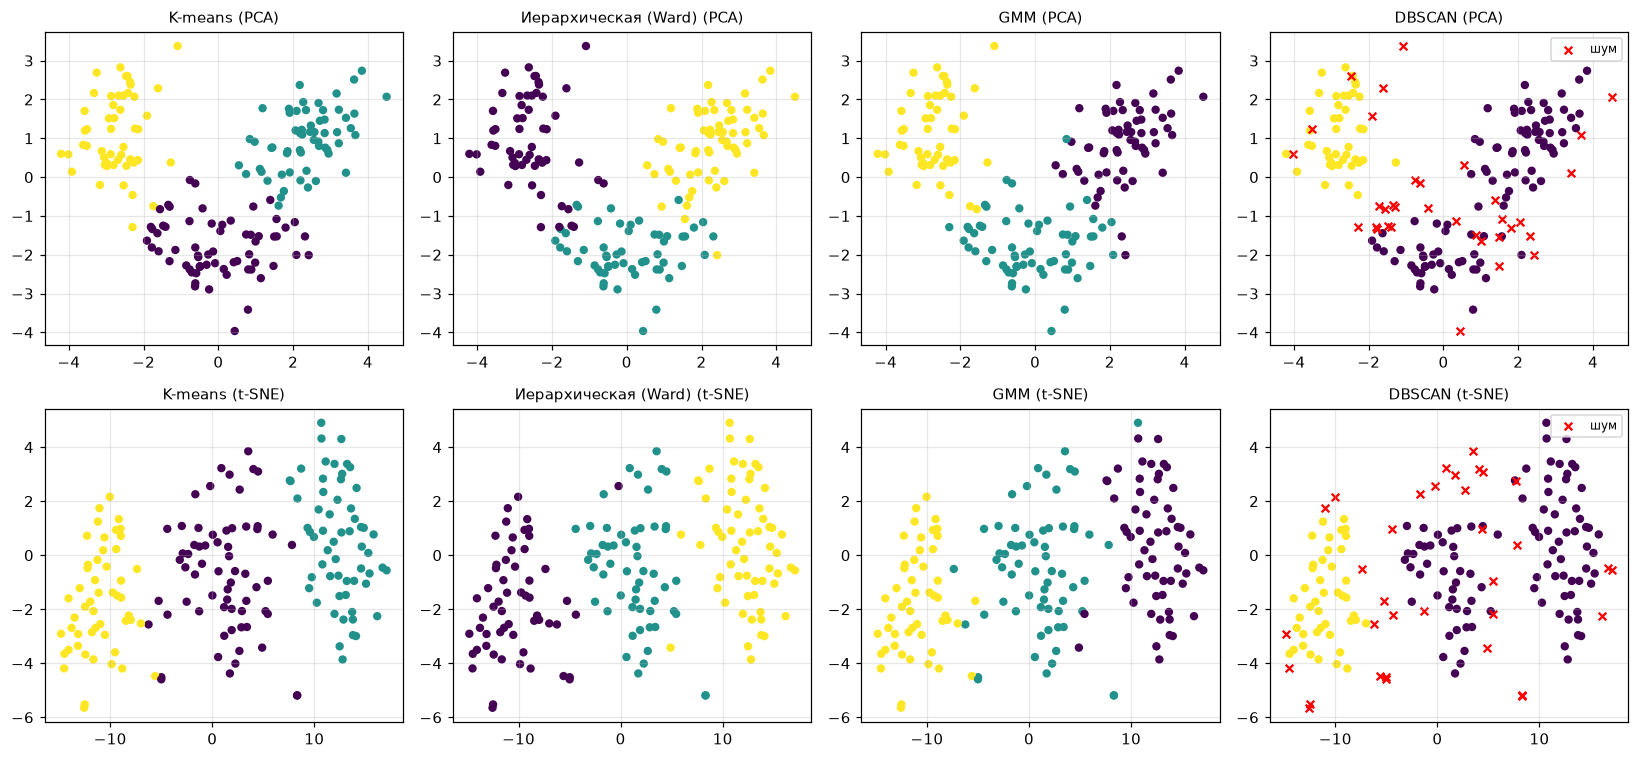

In [9]:
K = 3
models = {
    "K-means": KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit_predict(X),
    "Иерархическая (Ward)": AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X),
    "GMM": GaussianMixture(n_components=K, covariance_type="diag", n_init=5, random_state=RANDOM_STATE)
    .fit(X)
    .predict(X),
    "DBSCAN": DBSCAN(eps=EPS, min_samples=MS).fit_predict(X),
}

res = []
for name, lab in models.items():
    m = lab != -1
    n_cl = len(set(lab[m]))
    res.append(
        {
            "Алгоритм": name,
            "Кластеров": n_cl,
            "Шум, %": 100 * float(np.mean(~m)),
            "Silhouette": silhouette_score(X[m], lab[m]),
            "Davies-Bouldin": davies_bouldin_score(X[m], lab[m]),
            "Calinski-Harabasz": calinski_harabasz_score(X[m], lab[m]),
            "ARI": adjusted_rand_score(y_clean, lab),
            "NMI": normalized_mutual_info_score(y_clean, lab),
            "Homogeneity": homogeneity_score(y_clean, lab),
        }
    )
res_table = pd.DataFrame(res)
print(res_table.round(3).to_string(index=False))
res_table.to_csv(BASE / "results_summary.csv", index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for j, (name, lab) in enumerate(models.items()):
    for i, (emb, en) in enumerate([(X_pca, "PCA"), (X_tsne, "t-SNE")]):
        ax = axes[i, j]
        noise = lab == -1
        ax.scatter(emb[~noise, 0], emb[~noise, 1], c=lab[~noise], cmap="viridis", s=20)
        if noise.any():
            ax.scatter(emb[noise, 0], emb[noise, 1], c="red", marker="x", s=25, label="шум")
            ax.legend(loc="best", fontsize=8)
        ax.set_title(f"{name} ({en})", fontsize=10)
savefig("clusters_compare.png")

## Таблица сопоставления кластеров и классов лучшей модели

Сопоставление K-means и классов:
 Класс     0   1   2
Кластер            
0         0  64   0
1        59   0   0
2         0   3  48
         alcohol  flavanoids  proline  color_intensity
cluster                                               
0          12.25        2.07   510.02             2.99
1          13.74        2.98  1115.71             5.53
2          13.13        0.82   619.06             7.23


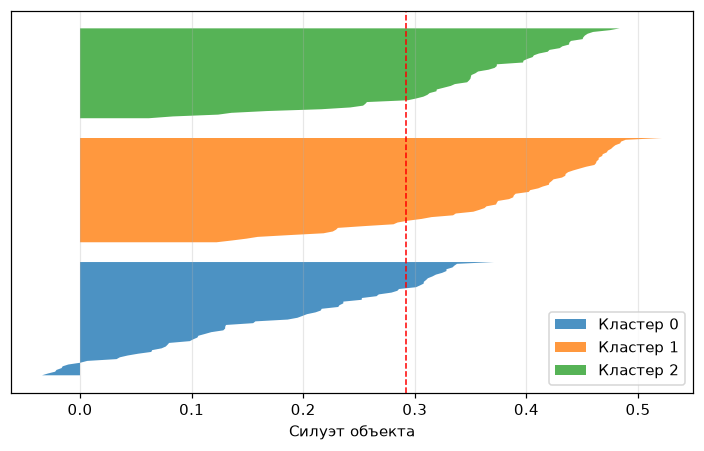

In [10]:
best_name = res_table.sort_values("Silhouette", ascending=False).iloc[0]["Алгоритм"]
ct = pd.crosstab(pd.Series(models["K-means"], name="Кластер"), pd.Series(y_clean.values, name="Класс"))
print("Сопоставление K-means и классов:\n", ct)

# Профили кластеров K-means в исходных единицах
prof = X_clean.assign(cluster=models["K-means"]).groupby("cluster").mean()
print(prof[["alcohol", "flavanoids", "proline", "color_intensity"]].round(2))

# Силуэт по объектам для K-means
from sklearn.metrics import silhouette_samples

sil = silhouette_samples(X, models["K-means"])
fig, ax = plt.subplots(figsize=(6.5, 4.2))
y_low = 10
for c in range(K):
    vals = np.sort(sil[models["K-means"] == c])
    ax.fill_betweenx(np.arange(y_low, y_low + len(vals)), 0, vals, alpha=0.8, label=f"Кластер {c}")
    y_low += len(vals) + 10
ax.axvline(sil.mean(), color="red", ls="--", lw=1)
ax.set_xlabel("Силуэт объекта")
ax.set_yticks([])
ax.legend()
savefig("silhouette_kmeans.png")

## 7. Кластеризация в пространстве главных компонент

PCA 90 %: компонент = 8


Исходные (13 признаков) DBSCAN eps, min_samples = (2.4, 5)


PCA, 8 компонент (90 % дисперсии) DBSCAN eps, min_samples = (2.0, 5)


PCA, 2 компоненты (57 % дисперсии) DBSCAN eps, min_samples = (0.6, 5)


t-SNE, 2 компоненты (perplexity 30) DBSCAN eps, min_samples = (1.5, 6)
                       Пространство             Алгоритм  Кластеров  Шум, %  Silhouette   ARI   NMI
            Исходные (13 признаков)              K-means          3   0.000       0.292 0.950 0.938
            Исходные (13 признаков) Иерархическая (Ward)          3   0.000       0.284 0.806 0.803
            Исходные (13 признаков)                  GMM          3   0.000       0.287 0.896 0.864
            Исходные (13 признаков)               DBSCAN          2  19.540       0.323 0.411 0.504
  PCA, 8 компонент (90 % дисперсии)              K-means          3   0.000       0.322 0.950 0.938
  PCA, 8 компонент (90 % дисперсии) Иерархическая (Ward)          3   0.000       0.316 0.865 0.847
  PCA, 8 компонент (90 % дисперсии)                  GMM          3   0.000       0.319 0.966 0.947
  PCA, 8 компонент (90 % дисперсии)               DBSCAN          2  19.540       0.366 0.398 0.506
 PCA, 2 компоненты (57 % дисп

 k  Silhouette  Davies-Bouldin  Calinski-Harabasz
 2       0.462           0.891            179.045
 3       0.560           0.599            335.327
 4       0.497           0.756            321.691
 5       0.451           0.735            303.798
 6       0.438           0.781            316.226
 7       0.423           0.789            328.486
 8       0.404           0.810            313.753
 9       0.392           0.852            300.492
10       0.398           0.820            298.489


t-SNE:
  k  Silhouette  Davies-Bouldin  Calinski-Harabasz
 2       0.583           0.550            444.404
 3       0.607           0.525            720.283
 4       0.512           0.719            602.405
 5       0.433           0.883            560.915
 6       0.366           0.972            528.163
 7       0.375           0.936            527.534
 8       0.398           0.848            537.418
 9       0.393           0.825            548.746
10       0.390           0.812            543.259


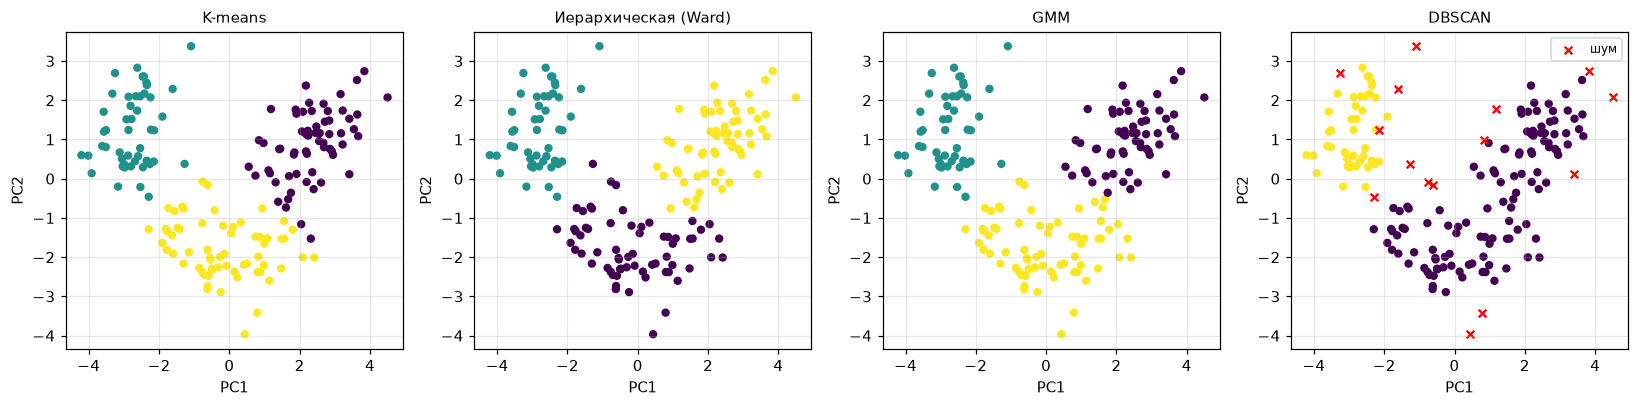

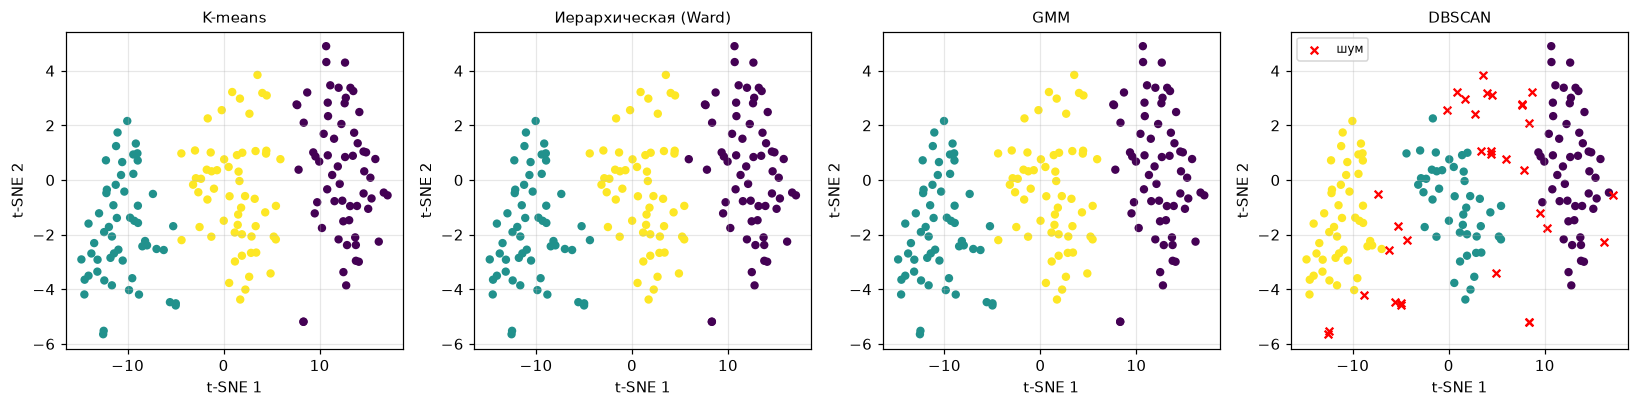

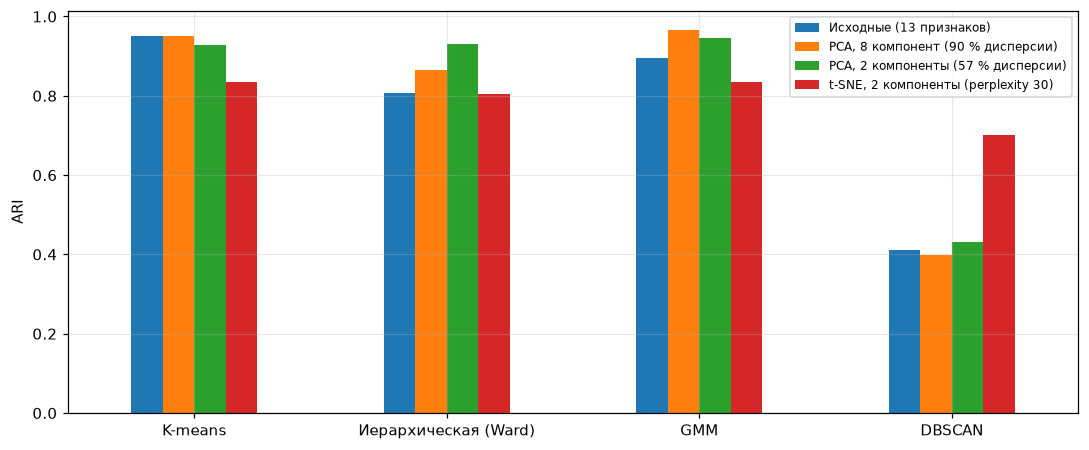

Готово.


In [11]:
def tune_dbscan(Z, y, eps_grid, ms_grid=(3, 4, 5, 6, 8, 10), max_noise=0.2):
    """Перебор eps и min_samples; выбор по силуэту без шума (>=2 кластеров, шум <= max_noise)."""
    best = None
    for eps in eps_grid:
        for ms in ms_grid:
            lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z)
            n_cl = len(set(lab)) - (1 if -1 in lab else 0)
            if n_cl < 2 or np.mean(lab == -1) > max_noise:
                continue
            m = lab != -1
            s = silhouette_score(Z[m], lab[m])
            if best is None or s > best[0]:
                best = (s, round(float(eps), 2), ms, lab)
    return best


def evaluate(Z, space_name, eps_grid=np.arange(0.3, 4.01, 0.1)):
    """Четыре алгоритма на матрице признаков Z; возвращает таблицу и метки."""
    _, eps_b, ms_b, db_lab = tune_dbscan(Z, y_clean, eps_grid)
    labs = {
        "K-means": KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit_predict(Z),
        "Иерархическая (Ward)": AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(Z),
        "GMM": GaussianMixture(n_components=K, covariance_type="diag", n_init=5, random_state=RANDOM_STATE)
        .fit(Z)
        .predict(Z),
        "DBSCAN": db_lab,
    }
    out = []
    for name, lab in labs.items():
        m = lab != -1
        out.append(
            {
                "Пространство": space_name,
                "Алгоритм": name,
                "Кластеров": len(set(lab[m])),
                "Шум, %": 100 * float(np.mean(~m)),
                "Silhouette": silhouette_score(Z[m], lab[m]),
                "ARI": adjusted_rand_score(y_clean, lab),
                "NMI": normalized_mutual_info_score(y_clean, lab),
            }
        )
    return pd.DataFrame(out), labs, (eps_b, ms_b)


# PCA, сохраняющий 90 % дисперсии, и двумерный PCA
pca90 = PCA(n_components=0.90, random_state=RANDOM_STATE)
X_pc90 = pca90.fit_transform(X)
print("PCA 90 %: компонент =", X_pc90.shape[1])

spaces = {
    f"Исходные ({X.shape[1]} признаков)": X,
    f"PCA, {X_pc90.shape[1]} компонент (90 % дисперсии)": X_pc90,
    "PCA, 2 компоненты (57 % дисперсии)": X_pca,
    "t-SNE, 2 компоненты (perplexity 30)": X_tsne,
}
# шкала t-SNE крупнее шкалы стандартизованных признаков, поэтому для неё сетка eps шире
eps_grids = {"t-SNE, 2 компоненты (perplexity 30)": np.arange(0.5, 8.01, 0.25)}
all_tables, all_labels, all_db = [], {}, {}
for sp, Z in spaces.items():
    tbl, labs, dbp = evaluate(Z, sp, eps_grids.get(sp, np.arange(0.3, 4.01, 0.1)))
    all_tables.append(tbl)
    all_labels[sp] = labs
    all_db[sp] = dbp
    print(sp, "DBSCAN eps, min_samples =", dbp)
space_table = pd.concat(all_tables, ignore_index=True)
print(space_table.round(3).to_string(index=False))
space_table.to_csv(BASE / "results_spaces.csv", index=False, encoding="utf-8-sig")

# Выбор k в двумерном PCA-пространстве
pc2_rows = []
for k in ks:
    lab = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_pca)
    pc2_rows.append(
        {
            "k": k,
            "Silhouette": silhouette_score(X_pca, lab),
            "Davies-Bouldin": davies_bouldin_score(X_pca, lab),
            "Calinski-Harabasz": calinski_harabasz_score(X_pca, lab),
        }
    )
print(pd.DataFrame(pc2_rows).round(3).to_string(index=False))

# Выбор k в пространстве t-SNE
tsne_rows = []
for k in ks:
    lab = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_tsne)
    tsne_rows.append(
        {
            "k": k,
            "Silhouette": silhouette_score(X_tsne, lab),
            "Davies-Bouldin": davies_bouldin_score(X_tsne, lab),
            "Calinski-Harabasz": calinski_harabasz_score(X_tsne, lab),
        }
    )
print("t-SNE:\n", pd.DataFrame(tsne_rows).round(3).to_string(index=False))


# Модели, обученные на двумерных данных, показаны в том же пространстве, где они обучались
def plot_trained(space_name, emb, xl, yl, fname):
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
    for ax, (name, lab) in zip(axes, all_labels[space_name].items()):
        noise = lab == -1
        ax.scatter(emb[~noise, 0], emb[~noise, 1], c=lab[~noise], cmap="viridis", s=20)
        if noise.any():
            ax.scatter(emb[noise, 0], emb[noise, 1], c="red", marker="x", s=25, label="шум")
            ax.legend(fontsize=8)
        ax.set_title(name, fontsize=10)
        ax.set_xlabel(xl)
        ax.set_ylabel(yl)
    savefig(fname)


plot_trained("PCA, 2 компоненты (57 % дисперсии)", X_pca, "PC1", "PC2", "clusters_pca_trained.png")
plot_trained("t-SNE, 2 компоненты (perplexity 30)", X_tsne, "t-SNE 1", "t-SNE 2", "clusters_tsne_trained.png")

# Сравнение ARI по пространствам
piv = space_table.pivot(index="Алгоритм", columns="Пространство", values="ARI")[list(spaces)]
piv = piv.loc[["K-means", "Иерархическая (Ward)", "GMM", "DBSCAN"]]
ax = piv.plot.bar(figsize=(10, 4.2), rot=0)
ax.set_ylabel("ARI")
ax.set_xlabel("")
ax.legend(fontsize=8)
savefig("ari_by_space.png")

print("Готово.")